# RoadScan — RF-DETR Small


In [2]:
# Locate the full repository in VS Code or Colab; never infer weights from unrelated folders.
from pathlib import Path
import os
import sys
import zipfile

def is_project(path):
    return (path / 'configs/project.example.json').is_file() and (path / 'src/roadscan/settings.py').is_file()

override = os.environ.get('ROADSCAN_ROOT')
if override:
    ROOT = Path(override).expanduser().resolve()
    if not is_project(ROOT):
        raise FileNotFoundError(f'ROADSCAN_ROOT is not a RoadScan project: {ROOT}')
else:
    candidates = [Path.cwd(), *Path.cwd().parents,
                  Path('/content/RoadScan_project/RoadScan_GitHub'),
                  Path('/content/RoadScan_GitHub')]
    ROOT = next((p for p in candidates if is_project(p)), None)
    if ROOT is None:
        archives = [Path('/content/RoadScan_GitHub_Detection_Fixed.zip'),
                    Path('/RoadScan_GitHub_Detection_Fixed.zip'),
                    Path('/content/RoadScan_GitHub.zip'), Path('/RoadScan_GitHub.zip')]
        archive = next((p for p in archives if p.is_file()), None)
        if archive is None:
            raise FileNotFoundError('Extract the full project or upload its ZIP and set ROADSCAN_ROOT if needed.')
        destination = Path('/content/RoadScan_project')
        destination.mkdir(parents=True, exist_ok=True)
        with zipfile.ZipFile(archive) as z:
            for member in z.infolist():
                if not (destination / member.filename).resolve().is_relative_to(destination.resolve()):
                    raise ValueError('Unsafe project archive path')
            z.extractall(destination)
        roots = [p.parent.parent for p in destination.rglob('configs/project.example.json') if is_project(p.parent.parent)]
        if len(roots) != 1:
            raise RuntimeError(f'Expected one extracted project, found {len(roots)}. Set ROADSCAN_ROOT explicitly.')
        ROOT = roots[0]

ROOT = ROOT.resolve()
os.chdir(ROOT)
if str(ROOT / 'src') not in sys.path:
    sys.path.insert(0, str(ROOT / 'src'))
from roadscan.settings import load_settings
settings = load_settings(ROOT)
print('Project root:', ROOT)
print('Bundled dataset:', settings['dataset_source'])
print('Bundled weights:', settings['rf_weights'])


Project root: C:\Users\ameer\Downloads\RoadScan_Detection_GitHub\RoadScan_Detection_GitHub\RoadScan_GitHub
Bundled dataset: C:\Users\ameer\Downloads\RoadScan_Detection_GitHub\RoadScan_Detection_GitHub\RoadScan_GitHub\RoadScan_Dataset_Final\RoadScan_Dataset
Bundled weights: C:\Users\ameer\Downloads\RoadScan_Detection_GitHub\RoadScan_Detection_GitHub\RoadScan_GitHub\models\rf_small_training\checkpoint_best_ema.pth


In [3]:
%pip install -q "rfdetr[train]==1.11.2" "transformers==5.1.0" "pycocotools==2.0.11" pandas matplotlib pyyaml pillow tqdm faiss-cpu scikit-learn ImageHash

Note: you may need to restart the kernel to use updated packages.


In [4]:
import os
os.environ['WANDB_DISABLED']='true'
os.environ['TOKENIZERS_PARALLELISM']='false'
import gc,sys,json,time,hashlib,shutil,zipfile,random,io,contextlib
from pathlib import Path
from importlib.metadata import version
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch,yaml
from rfdetr import RFDETRSmall
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval
from tqdm.auto import tqdm
from IPython.display import display
# Local VS Code: no Google Drive mount required.
assert version('rfdetr')=='1.11.2' and version('transformers')=='5.1.0','Restart session after installation; continue from imports.'
print('PyTorch:',torch.__version__,'| GPU:',torch.cuda.is_available())

PyTorch: 2.13.0+cu130 | GPU: True


## 1. Paths and execution switches
Defaults use the bundled models/rf_small_training/checkpoint_best_ema.pth and RoadScan_Dataset_Final/RoadScan_Dataset. MODE="load" never trains. RUN_DETECTION_EVALUATION=True creates the missing validation-selected frozen_selection.json before running final tests. Save reports/rf_appready to Drive after completion because Colab local storage is temporary.

To reuse an existing selection later, disable evaluation only after setting VALIDATED_SELECTION_SOURCE to the matching saved file; its checkpoint hash, class order and resolution are checked. MODE="resume" requires the bundled last.ckpt and matching training/data identity; it is an explicit action, never an automatic fallback. App/duplicate export is optional.


In [7]:
BASE=ROOT
DATA_SOURCE=settings['dataset_source']
MODE="load"  # "resume" saved full state, "train" a new run, or "load" saved weights.
assert MODE in {"resume", "train", "load"}
RF_BACKUP=Path(settings['rf_backup'])  # Optional fallback; bundled run folder is preferred.
RESUME_RUN_SOURCE=settings['rf_run_source']  # Optional original training folder; copied into the independent output once.
EXISTING_RF_BEST=settings['rf_weights'] if MODE == 'load' else ''  # Optional trusted, fine-tuned RF-DETR Small checkpoint.
OUTPUT=settings['output_dir']  ## NEW: separate continuation output
LOCAL=settings['work_dir']  ## NEW
RF_RUN=OUTPUT/'rf_small_training'  # Keep fixed across runtime restarts.
RF_EPOCHS=20  ## NEW: TOTAL target, not 20 additional epochs
assert RF_EPOCHS == 20, "This notebook is configured for 20 TOTAL epochs."  ## NEW
RF_RESOLUTION=512
RF_BATCH=4
RF_ACCUMULATION=4
INFERENCE_DEVICE='cuda:0' if torch.cuda.is_available() else 'cpu'
SEED, MAX_DET=42,300
CONF_FLOOR=0.001
IOU_LEVELS=np.linspace(0.5,0.95,10)
THRESHOLD_GRID=np.round(np.arange(0.05,0.81,0.01),2)
CLASS_NAMES=['longitudinal_crack','transverse_crack','alligator_crack','pothole']
CODES=['D00','D10','D20','D40']; NC=4
EXCLUDE_EMPTY_SAUDI=True  # Exclude unconfirmed empty labels if present; current Saudi100 has none.
for folder in [OUTPUT,LOCAL,RF_RUN]: folder.mkdir(parents=True,exist_ok=True)
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
torch.set_num_threads(min(4,os.cpu_count() or 1))

def save_json(path,obj):
    path=Path(path); path.parent.mkdir(parents=True,exist_ok=True)
    temp=path.with_suffix(path.suffix+'.tmp')
    temp.write_text(json.dumps(obj,indent=2,allow_nan=False),encoding='utf-8')
    temp.replace(path)

def file_hash(path):
    h=hashlib.sha256()
    with Path(path).open('rb') as f:
        for chunk in iter(lambda:f.read(1024*1024),b''): h.update(chunk)
    return h.hexdigest()


def directory_hash(folder):
    h=hashlib.sha256()
    for p in sorted(Path(folder).rglob('*')):
        if p.is_file(): h.update((p.relative_to(folder).as_posix()+file_hash(p)).encode())
    return h.hexdigest()

## NEW: independent switches; app export does not require the detector dataset.
RUN_DETECTION_EVALUATION = True  # Missing frozen selection is computed on validation, not guessed.
RUN_APP_EXPORT = False  # Enable only for the DINOv2/application package.
RUN_DUPLICATE_EVALUATION = False
RUN_SIMULATED_REPLAY = False
RUN_APP_SMOKE_EXAMPLE = False
VALIDATED_SELECTION_SOURCE = settings['frozen_selection']
DUPLICATE_PAIRS_CSV = settings['duplicate_pairs']
APP_STATE = settings['state_dir']  # Never use the simulated replay directory for real reports.
APP_EXAMPLE_IMAGE = ''
APP_EXAMPLE_LATITUDE = None
APP_EXAMPLE_LONGITUDE = None
assert MODE == 'load' or RUN_DETECTION_EVALUATION, 'Enable detector validation/evaluation for a training run.'
# Fail early on missing inputs and show actual paths before loading the detector.
if MODE == 'load' and (not EXISTING_RF_BEST or not Path(EXISTING_RF_BEST).is_file()):
    raise FileNotFoundError(f'Saved weights missing: {EXISTING_RF_BEST}. Check configs/project.local.json overrides.')
if RUN_DETECTION_EVALUATION or MODE != 'load':
    if not Path(DATA_SOURCE).exists():
        raise FileNotFoundError(f'Dataset missing: {DATA_SOURCE}. Keep the bundled dataset folder with the project.')
if not RUN_DETECTION_EVALUATION and not Path(VALIDATED_SELECTION_SOURCE).is_file():
    raise FileNotFoundError('No saved frozen_selection.json. Enable RUN_DETECTION_EVALUATION to select thresholds on RDD validation.')
if (RUN_DUPLICATE_EVALUATION or RUN_SIMULATED_REPLAY or RUN_APP_SMOKE_EXAMPLE) and not RUN_APP_EXPORT:
    raise ValueError('Enable RUN_APP_EXPORT before duplicate evaluation, replay or the app example.')
print('Mode:', MODE, '| detector evaluation:', RUN_DETECTION_EVALUATION, '| app export:', RUN_APP_EXPORT)
print('Weight source:', EXISTING_RF_BEST if MODE == 'load' else RESUME_RUN_SOURCE)
print('Validation selection output:', OUTPUT / 'frozen_selection.json')

# Keep the approved Saudi100 dataset fixed; checkpoints retain their original history.
identity_path = Path(settings['rf_run_source']) / 'roadscan_training_identity.json'
SAVED_TRAINING_IDENTITY = json.loads(identity_path.read_text(encoding='utf-8')) if identity_path.is_file() else None
if MODE == 'load':
    print('Loading saved weights for evaluation; the bundled checkpoint training data differs from the approved dataset.')


Mode: load | detector evaluation: True | app export: False
Weight source: C:\Users\ameer\Downloads\RoadScan_Detection_GitHub\RoadScan_Detection_GitHub\RoadScan_GitHub\models\rf_small_training\checkpoint_best_ema.pth
Validation selection output: C:\Users\ameer\Downloads\RoadScan_Detection_GitHub\RoadScan_Detection_GitHub\RoadScan_GitHub\reports\rf_appready\frozen_selection.json
Loading saved weights for evaluation; the bundled checkpoint training data differs from the approved dataset.


## 2. Dataset preparation for evaluation

In [8]:
if RUN_DETECTION_EVALUATION or MODE != 'load':
    assert DATA_SOURCE.exists(), f'Dataset not found: {DATA_SOURCE}'
    if DATA_SOURCE.is_file():
        signature=hashlib.sha256(str((str(DATA_SOURCE), DATA_SOURCE.stat().st_size,
                                   DATA_SOURCE.stat().st_mtime_ns)).encode()).hexdigest()[:16]
        folder=LOCAL/signature
        marker=folder/'extraction_complete.json'
        if not marker.exists():
            local_zip=LOCAL/'dataset.zip'; shutil.copy2(DATA_SOURCE, local_zip)
            folder.mkdir(exist_ok=True)
            with zipfile.ZipFile(local_zip) as z:
                for member in z.infolist():
                    if not (folder/member.filename).resolve().is_relative_to(folder.resolve()):
                        raise ValueError('Unsafe archive path')
                z.extractall(folder)
            save_json(marker, {'complete':True})
    else:
        folder=DATA_SOURCE
    roots={p.parent for p in folder.rglob('images') if (p.parent/'labels').is_dir()}
    if (folder/'images').is_dir() and (folder/'labels').is_dir(): roots.add(folder)
    assert len(roots)==1, f'Expected one dataset root: {roots}'
    DATA_ROOT=next(iter(roots))
    names=yaml.safe_load((DATA_ROOT/'data.yaml').read_text())['names']
    if isinstance(names, dict): names=[names.get(i,names.get(str(i))) for i in range(NC)]
    assert names==CLASS_NAMES, f'Unexpected class order: {names}'

    def labels_for(path, split):
        return DATA_ROOT/'labels'/split/path.relative_to(DATA_ROOT/'images'/split).with_suffix('.txt')

    def read_truth(path, split):
        label=labels_for(path, split)
        rows=np.asarray([list(map(float,line.split())) for line in label.read_text().splitlines()
                         if line.strip()], dtype=float).reshape(-1,5)
        if len(rows):
            assert np.isfinite(rows).all() and (rows[:,0]==rows[:,0].astype(int)).all()
            assert ((rows[:,0]>=0)&(rows[:,0]<NC)).all()
            assert ((rows[:,1:]>=0)&(rows[:,1:]<=1)).all() and (rows[:,3:]>0).all()
            assert (rows[:,1:3]-rows[:,3:]/2>=-1e-4).all()
            assert (rows[:,1:3]+rows[:,3:]/2<=1.0001).all()
        with Image.open(path) as im:
            w,h=im.size
            assert int(im.getexif().get(274,1)) in (0,1), 'Normalize orientation and labels first.'
        truth=rows.copy()
        if len(rows):
            truth[:,1:3]=(rows[:,1:3]-rows[:,3:]/2)*[w,h]
            truth[:,3:5]=(rows[:,1:3]+rows[:,3:]/2)*[w,h]
        return truth

    PATHS={}; exclusions=[]; data_hasher=hashlib.sha256()
    for split in ['val','test','saudi_test']:
        images=sorted(p for p in (DATA_ROOT/'images'/split).rglob('*')
                      if p.suffix.lower() in {'.jpg','.jpeg','.png','.bmp','.webp'})
        assert images, f'Empty split: {split}'
        kept=[]
        for p in tqdm(images, desc=f'Checking {split}'):
            truth=read_truth(p,split)
            data_hasher.update((p.relative_to(DATA_ROOT).as_posix()+file_hash(p)).encode())
            data_hasher.update(labels_for(p,split).read_bytes())
            if split=='saudi_test' and EXCLUDE_EMPTY_SAUDI and not len(truth):
                exclusions.append({'image':p.name,'reason':'Unconfirmed empty Saudi annotation; excluded by explicit policy'})
            else: kept.append(p)
        PATHS[split]=kept
    DATA_HASH=data_hasher.hexdigest()
    save_json(OUTPUT/'exclusions.json', exclusions)
    display(pd.DataFrame([{'split':s,'images':len(p)} for s,p in PATHS.items()]))
if RUN_DETECTION_EVALUATION or MODE != 'load':
    # Fingerprint actual approved train/val bytes, respecting the current quarantine.
    quarantine_path = DATA_ROOT / 'training_quarantine.csv'
    blocked_for_identity = set(pd.read_csv(quarantine_path)['image']) if quarantine_path.is_file() else set()
    training_identity_hasher = hashlib.sha256()
    for identity_split in ('train', 'val'):
        for identity_image in sorted((DATA_ROOT / 'images' / identity_split).rglob('*')):
            if not identity_image.is_file() or identity_image.suffix.lower() not in {'.jpg','.jpeg','.png','.bmp','.webp'}:
                continue
            identity_relative = identity_image.relative_to(DATA_ROOT).as_posix()
            if identity_split == 'train' and identity_relative in blocked_for_identity:
                continue
            training_identity_hasher.update((identity_relative + file_hash(identity_image)).encode())
            training_identity_hasher.update(labels_for(identity_image, identity_split).read_bytes())
    APPROVED_TRAINING_HASH = training_identity_hasher.hexdigest()


Checking val:   0%|          | 0/797 [00:00<?, ?it/s]

Checking test:   0%|          | 0/799 [00:00<?, ?it/s]

Checking saudi_test:   0%|          | 0/100 [00:00<?, ?it/s]

,split,images
0,val,797
1,test,799
2,saudi_test,100


In [9]:
if RUN_DETECTION_EVALUATION or MODE != 'load':
    if MODE in {"train","resume"}:
        # The RF training dataset physically contains RDD train and validation only.
        train_images=sorted(p for p in (DATA_ROOT/'images/train').rglob('*')
            if p.suffix.lower() in {'.jpg','.jpeg','.png','.bmp','.webp'})
        quarantine_file=DATA_ROOT/'training_quarantine.csv'
        assert quarantine_file.is_file(), 'Use the validated dataset archive with its original training quarantine.'
        blocked=set(pd.read_csv(quarantine_file)['image'])
        available={p.relative_to(DATA_ROOT).as_posix() for p in train_images}
        assert blocked<=available, 'Quarantine references unknown training images.'
        train_images=[p for p in train_images if p.relative_to(DATA_ROOT).as_posix() not in blocked]
        assert train_images, 'No training images left.'
        TRAIN_DATA=LOCAL/'rf_coco_trainval'
        train_hasher=hashlib.sha256()
        manifest=[]
        for split,paths,dest_split in [('train',train_images,'train'),('val',PATHS['val'],'valid')]:
            dest=TRAIN_DATA/dest_split; dest.mkdir(parents=True,exist_ok=True)
            images=[]; annotations=[]
            for index,p in enumerate(tqdm(paths,desc=f'Preparing RDD {split}')):
                truth=read_truth(p,split)
                with Image.open(p) as im: w,h=im.size
                filename=f'{index:06d}{p.suffix.lower()}'
                target=dest/filename
                if target.is_symlink() and target.resolve()!=p.resolve(): target.unlink()
                if not target.exists():
                    try: target.symlink_to(p.resolve())
                    except OSError: shutil.copy2(p,target)
                images.append(dict(id=index+1,file_name=filename,width=w,height=h))
                for c,x1,y1,x2,y2 in truth:
                    annotations.append(dict(id=len(annotations)+1,image_id=index+1,category_id=int(c),
                        bbox=[float(x1),float(y1),float(x2-x1),float(y2-y1)],
                        area=float((x2-x1)*(y2-y1)),iscrowd=0))
                digest=file_hash(p)
                train_hasher.update((p.relative_to(DATA_ROOT).as_posix()+digest).encode())
                train_hasher.update(labels_for(p,split).read_bytes())
                manifest.append(dict(split=split,image=p.relative_to(DATA_ROOT).as_posix(),sha256=digest))
            save_json(dest/'_annotations.coco.json',dict(info={},licenses=[],images=images,
                annotations=annotations,categories=[dict(id=i,name=name,supercategory='road_damage')
                    for i,name in enumerate(CLASS_NAMES)]))
        TRAIN_HASH=train_hasher.hexdigest()
        # Exact continuation cannot silently switch to the approved dataset.
        if MODE == "resume":
            identity_file = RF_RUN / "roadscan_training_identity.json"
            if not identity_file.is_file() and RESUME_RUN_SOURCE:
                identity_file = Path(RESUME_RUN_SOURCE) / "roadscan_training_identity.json"
            if not identity_file.is_file():
                raise FileNotFoundError("Resume requires the original saved training identity.")
            saved_identity = json.loads(identity_file.read_text(encoding="utf-8"))
            if saved_identity.get("train_hash") != TRAIN_HASH:
                raise RuntimeError("Resume blocked: checkpoint and approved dataset fingerprints differ. No earlier dataset was restored. Use load for exploratory evaluation, or a separate new training run; never edit the saved fingerprint.")
        assert not (TRAIN_DATA/'test').exists(), 'RF training folder must have no test split.'
        assert all(m['image'].startswith(('images/train/','images/val/')) for m in manifest)
        pd.DataFrame(manifest).to_csv(OUTPUT/'rf_trainval_manifest.csv',index=False)
        save_json(OUTPUT/'dataset_identity.json',dict(training_hash=TRAIN_HASH,evaluation_hash=DATA_HASH,
            train_images=len(train_images),val_images=len(PATHS['val']),saudi_images=len(PATHS['saudi_test']),
            quarantine_images=len(blocked),classes=CLASS_NAMES))
        print('RDD train:',len(train_images),'RDD validation:',len(PATHS['val']))

    else:
        save_json(OUTPUT/'dataset_identity.json',dict(evaluation_hash=DATA_HASH,
            val_images=len(PATHS['val']),test_images=len(PATHS['test']),
            saudi_images=len(PATHS['saudi_test']),classes=CLASS_NAMES,
            mode='saved-model evaluation; no training-data preparation'))
        print('Training-data preparation skipped. Saved-model evaluation only.')

Training-data preparation skipped. Saved-model evaluation only.


## 3. Load or resume RF-DETR

This controller reads the actual completed epoch from the checkpoint, uses 20 as the total budget,
and skips further training if that budget has already been reached. Exact resume requires the
original dataset/training identity, optimizer and scheduler state. A changed total schedule is an
extension of the earlier run, not evidence that it was originally scheduled for 20 epochs.
The source run is preserved; the new output directory is independent.

In [10]:
def extract_rf_backup():
    if RESUME_RUN_SOURCE:
        origin=Path(RESUME_RUN_SOURCE)
        if not origin.is_dir(): raise FileNotFoundError(f'Resume folder not found: {origin}')
        return origin
    if not RF_BACKUP.is_file(): return None
    destination=LOCAL/'rf_backup'/file_hash(RF_BACKUP)[:16]
    marker=destination/'extracted.json'
    if not marker.exists():
        destination.mkdir(parents=True,exist_ok=True)
        with zipfile.ZipFile(RF_BACKUP) as archive:
            for member in archive.infolist():
                if not (destination/member.filename).resolve().is_relative_to(destination.resolve()):
                    raise ValueError('Unsafe archive path in RF backup.')
            archive.extractall(destination)
        save_json(marker,{'source':str(RF_BACKUP)})
    return destination

def find_best(root):
    if root is None or not Path(root).is_dir(): return None
    for name in ['checkpoint_best_total.pth','checkpoint_best_ema.pth','checkpoint_best_regular.pth']:
        matches=sorted(Path(root).rglob(name))
        if len(matches)>1: raise ValueError(f'Multiple {name} files: {matches}')
        if matches: return matches[0]
    return None

def load_rf_weights():
    if EXISTING_RF_BEST:
        path=Path(EXISTING_RF_BEST)
        if not path.is_file(): raise FileNotFoundError(f'RF weights not found: {path}')
        return path
    # Prefer the active run, which may be newer than the saved backup.
    best=find_best(RF_RUN)
    if best is None: best=find_best(extract_rf_backup())
    if best is None:
        raise FileNotFoundError('No RF weights found. Check RF_BACKUP or EXISTING_RF_BEST. No training was started.')
    return best

def full_checkpoint(root):
    root=Path(root)
    if (root/'last.ckpt').is_file(): return root/'last.ckpt'
    candidates=[]
    for path in root.glob('checkpoint_*.ckpt'):
        suffix=path.stem.removeprefix('checkpoint_')
        if suffix.isdigit(): candidates.append((int(suffix),path))
    return max(candidates,key=lambda x:x[0])[1] if candidates else None

def restore_training_if_needed():
    if full_checkpoint(RF_RUN) is not None: return
    # Do not overwrite an active partial run with an older backup.
    if find_best(RF_RUN) is not None: return
    backup=extract_rf_backup()
    if backup is None: return
    matches=list(backup.rglob('last.ckpt'))
    if len(matches)>1: raise ValueError('Multiple resume checkpoints in backup.')
    if not matches: return
    origin=matches[0].parent
    if not (origin/'roadscan_training_identity.json').is_file():
        raise FileNotFoundError('Backup lacks training identity. Use MODE="load" for evaluation.')
    for path in origin.iterdir():
        if path.is_file() and (path.name=='last.ckpt' or path.name.startswith('checkpoint_best_')
                              or path.suffix in {'.json','.csv','.yaml'}):
            shutil.copy2(path,RF_RUN/path.name)
    print('Restored full RF training state from backup.')

def make_rf_train_args():
    # Called only after MODE="train" and training-data preparation.
    return dict(dataset_dir=str(TRAIN_DATA),dataset_file='roboflow',output_dir=str(RF_RUN),
        epochs=RF_EPOCHS,batch_size=RF_BATCH,grad_accum_steps=RF_ACCUMULATION,
        eval_batch_size=RF_BATCH,lr=1e-4,lr_encoder=1.5e-4,lr_scheduler='cosine',
        warmup_epochs=1.0,multi_scale=False,expanded_scales=False,use_ema=True,
        eval_base_model=False,checkpoint_interval=5,early_stopping=False,run_test=False,
        num_workers=2,seed=SEED,class_names=CLASS_NAMES,amp_dtype='auto',tensorboard=False,
        wandb=False,progress_bar='tqdm',eval_interval=1,eval_max_dets=MAX_DET,
        save_dataset_grids=False)

def normalized_identity(identity):
    identity=json.loads(json.dumps(identity))
    identity.pop('torch',None)
    args=identity.get('args',{})
    for key in ['epochs','dataset_dir','output_dir']: args.pop(key,None)
    return identity

def validate_training_identity(current):
    config=RF_RUN/'roadscan_training_identity.json'
    old=json.loads(config.read_text()) if config.exists() else None
    checkpoint=full_checkpoint(RF_RUN)
    if old is None and (checkpoint is not None or find_best(RF_RUN) is not None):
        raise RuntimeError('Saved training identity missing. Restore it, or choose MODE="load".')
    if old is not None:
        before=normalized_identity(old);after=normalized_identity(current)
        differences=[]
        for key in sorted(set(before)|set(after)):
            if key=='args':
                a,b=before.get(key,{}),after.get(key,{})
                differences.extend((f'args.{k}',a.get(k),b.get(k)) for k in sorted(set(a)|set(b)) if a.get(k)!=b.get(k))
            elif before.get(key)!=after.get(key):differences.append((key,before.get(key),after.get(key)))
        if differences:
            for key,a,b in differences:print(f'{key}: saved={a!r} | current={b!r}')
            raise RuntimeError('Actual data/training configuration changed. Checkpoints preserved. Restore settings or use MODE="load".')
    # Record the current requested total without treating it as a new training run.
    save_json(config,current)
    save_json(RF_RUN/'runtime_current.json',dict(torch=str(torch.__version__),rfdetr=version('rfdetr'),
        requested_total_epochs=RF_EPOCHS))

def plan_training(completed,target,has_checkpoint,has_saved_weights):
    if not 1<=target<=50: raise ValueError('Total epoch budget must be 1..50.')
    if has_checkpoint:
        return 'skip' if completed>=target else 'resume'
    if has_saved_weights:
        raise RuntimeError('Only best weights are available. Use MODE="load", or restore last.ckpt to resume without restarting.')
    return 'start'

def run_rf_mode():
    if MODE=='load':
        path=load_rf_weights()
        print('LOAD MODE — saved RF weights selected; training is not called:',path)
        return path
    if MODE not in {'train','resume'}: raise ValueError('MODE must be resume, train or load.')
    if EXISTING_RF_BEST:
        raise ValueError('EXISTING_RF_BEST is for MODE="load". Use the run/backup full checkpoint for MODE="train".')
    if MODE=='resume': restore_training_if_needed()
    checkpoint=full_checkpoint(RF_RUN)
    if MODE=='resume' and checkpoint is None:
        raise FileNotFoundError('Resume requires last.ckpt and its original training identity. Set RF_BACKUP or RESUME_RUN_SOURCE. Best .pth alone is for MODE=load; no training was started.')
    completed=0
    if checkpoint is not None:
        state=torch.load(checkpoint,map_location='cpu',weights_only=False)
        completed=int(state['epoch'])+1
        del state;gc.collect()
    ## NEW: checkpoint is the source of truth; 13 completed -> 7 remaining.
    print(f'Completed in checkpoint: {completed} | TOTAL target: {RF_EPOCHS} | Remaining: {max(0, RF_EPOCHS-completed)}')
    best=find_best(RF_RUN)
    action=plan_training(completed,RF_EPOCHS,checkpoint is not None,best is not None)
    if action=='skip':
        if best is None: raise FileNotFoundError('Training reached its budget but best weights are missing. Restore best checkpoint.')
        print(f'Already completed {completed} epochs; requested {RF_EPOCHS}. No additional training.')
        return best
    args=make_rf_train_args()
    identity=dict(model='RFDETRSmall',resolution=RF_RESOLUTION,train_hash=TRAIN_HASH,
        args={k:v for k,v in args.items() if k not in ['dataset_dir','output_dir']},rfdetr=version('rfdetr'))
    validate_training_identity(identity)
    if not torch.cuda.is_available():
        raise RuntimeError('GPU required for training/resume. Choose a GPU runtime or use MODE="load".')
    model=RFDETRSmall(resolution=RF_RESOLUTION,device='cuda')
    try:
        if action=='resume':args['resume']=str(checkpoint)
        print(f'{action.upper()}: completed={completed}, requested TOTAL={RF_EPOCHS}; never additional epochs.')
        model.train(device='cuda',**args)
        checkpoint=full_checkpoint(RF_RUN)
        if checkpoint is None:raise RuntimeError('Training produced no full checkpoint. Do not restart blindly.')
        state=torch.load(checkpoint,map_location='cpu',weights_only=False)
        completed=int(state['epoch'])+1;del state;gc.collect()
        if completed<RF_EPOCHS:
            raise RuntimeError(f'Training stopped after {completed} completed epochs. Rerun MODE="train" to resume.')
        best=find_best(RF_RUN)
        if best is None:raise FileNotFoundError('Best RF weights missing after training.')
        save_json(RF_RUN/'completed.json',dict(completed_epochs=completed,requested_total=RF_EPOCHS,best_weights=str(best)))
        return best
    finally:
        del model;gc.collect();torch.cuda.empty_cache()

RF_BEST=run_rf_mode()
print('RF weights:',RF_BEST)
# Read identity beside the selected weights, including newly trained output runs.
selected_identity_path = Path(RF_BEST).parent / 'roadscan_training_identity.json'
SELECTED_TRAINING_IDENTITY = json.loads(selected_identity_path.read_text(encoding='utf-8')) if selected_identity_path.is_file() else None


LOAD MODE — saved RF weights selected; training is not called: C:\Users\ameer\Downloads\RoadScan_Detection_GitHub\RoadScan_Detection_GitHub\RoadScan_GitHub\models\rf_small_training\checkpoint_best_ema.pth
RF weights: C:\Users\ameer\Downloads\RoadScan_Detection_GitHub\RoadScan_Detection_GitHub\RoadScan_GitHub\models\rf_small_training\checkpoint_best_ema.pth


## 4. Shared inference and evaluation functions

In [11]:
import json
from pathlib import Path
import numpy as np
from PIL import Image
from rfdetr import RFDETRSmall
def clean_predictions(pred,width,height,max_det=300):
    pred=np.asarray(pred,dtype=float).reshape(-1,6).copy()
    if not np.isfinite(pred).all(): raise ValueError('Non-finite detector output.')
    if len(pred):
        if not ((pred[:,5]==pred[:,5].astype(int))&(pred[:,5]>=0)&(pred[:,5]<4)).all():
            raise ValueError('Unexpected class IDs; expected 0..3.')
        if not ((pred[:,4]>=0)&(pred[:,4]<=1)).all(): raise ValueError('Invalid confidence values.')
        pred[:,[0,2]]=np.clip(pred[:,[0,2]],0,width)
        pred[:,[1,3]]=np.clip(pred[:,[1,3]],0,height)
        pred=pred[(pred[:,2]>pred[:,0])&(pred[:,3]>pred[:,1])]
    return pred[np.argsort(-pred[:,4],kind='stable')[:max_det]]

class RoadScanRF:
    def __init__(self,weights,classes,device='cpu',resolution=512,conf_floor=0.001,max_det=300):
        self.classes=list(classes); self.floor=conf_floor; self.max_det=max_det
        self.model=RFDETRSmall.from_checkpoint(str(weights),device=device,resolution=resolution,trust_checkpoint=True)
        if list(self.model.class_names)!=self.classes: raise ValueError(f'RF class mapping mismatch: {self.model.class_names}')
    def raw(self,image):
        with Image.open(image) as im: rgb=im.convert('RGB')
        detections=self.model.predict(rgb,threshold=self.floor)
        if not len(detections.xyxy): return np.empty((0,6),dtype=float)
        ids=np.asarray(detections.class_id)
        names=np.asarray(detections.data.get('class_name',['']*len(ids)),dtype=object)
        valid=(ids>=0)&(ids<len(self.classes))
        background=(ids==len(self.classes))&(names=='__background__')
        unexpected=~(valid|background)
        if unexpected.any(): raise ValueError(f'Unexpected RF classes: {ids[unexpected].tolist()}, names: {names[unexpected].tolist()}')
        pred=np.column_stack([detections.xyxy,detections.confidence,ids])[valid]
        return clean_predictions(pred,rgb.width,rgb.height,self.max_det)
    def predict(self,image,config):
        pred=self.raw(image);thresholds=np.asarray(config['thresholds'])
        return pred[pred[:,4]>=thresholds[pred[:,5].astype(int)]]

def load_deployment(folder,device='cpu'):
    folder=Path(folder);config=json.loads((folder/'deployment_config.json').read_text())
    detector=RoadScanRF(folder/'rf_small.pth',config['class_names'],device=device,
        resolution=config['rf_resolution'],conf_floor=config['confidence_floor'],max_det=config['max_det'])
    return detector,config

In [12]:
def box_iou(a,b):
    a=np.asarray(a).reshape(-1,4); b=np.asarray(b).reshape(-1,4)
    lo=np.maximum(a[:,None,:2],b[None,:,:2]); hi=np.minimum(a[:,None,2:],b[None,:,2:])
    inter=np.maximum(hi-lo,0).prod(2)
    aa=np.maximum(a[:,2:]-a[:,:2],0).prod(1)
    bb=np.maximum(b[:,2:]-b[:,:2],0).prod(1)
    return inter/np.maximum(aa[:,None]+bb[None,:]-inter,1e-12)

def match(truth,pred,levels=IOU_LEVELS):
    flags=np.zeros((len(pred),len(levels)),dtype=bool)
    overlaps=box_iou(pred[:,:4],truth[:,1:])
    for j,level in enumerate(levels):
        used=set()
        for i in np.argsort(-pred[:,4],kind='stable'):
            candidates=[g for g in range(len(truth)) if g not in used
                and int(truth[g,0])==int(pred[i,5]) and overlaps[i,g]>=level]
            if candidates:
                g=max(candidates,key=lambda g:overlaps[i,g]); used.add(g); flags[i,j]=True
    return flags

def packed(records):
    if isinstance(records, tuple): return records
    pred=np.concatenate([r['pred'] for r in records])
    target=np.concatenate([r['truth'][:,0] for r in records]).astype(int)
    for r in records:
        if 'matches' not in r: r['matches']=match(r['truth'],r['pred'])
    tp=np.concatenate([r['matches'] for r in records])
    return pred,target,tp

def operating(records,thresholds):
    pred,target,tp=packed(records)
    cls=pred[:,5].astype(int); thresholds=np.broadcast_to(thresholds,(NC,))
    keep=pred[:,4]>=thresholds[cls]
    support=np.bincount(target,minlength=NC)
    detected=np.bincount(cls[keep],minlength=NC)
    true=np.bincount(cls[keep & tp[:,0]],minlength=NC)
    p=true/np.maximum(detected,1); r=true/np.maximum(support,1)
    f=2*p*r/np.maximum(p+r,1e-12)
    return dict(P=p,R=r,F1=f,TP=true,FP=detected-true,FN=support-true,support=support)

def ap_scores(records):
    images=[]; annotations=[]; detections=[]
    for image_id,rec in enumerate(records,1):
        images.append(dict(id=image_id,width=rec['width'],height=rec['height']))
        for c,x1,y1,x2,y2 in rec['truth']:
            annotations.append(dict(id=len(annotations)+1,image_id=image_id,category_id=int(c),
                bbox=[float(x1),float(y1),float(x2-x1),float(y2-y1)],
                area=float((x2-x1)*(y2-y1)),iscrowd=0))
        for x1,y1,x2,y2,score,c in rec['pred']:
            detections.append(dict(image_id=image_id,category_id=int(c),score=float(score),
                bbox=[float(x1),float(y1),float(max(0,x2-x1)),float(max(0,y2-y1))]))
    ap=np.zeros((NC,10))
    if not detections: return ap
    with contextlib.redirect_stdout(io.StringIO()):
        gt=COCO(); gt.dataset=dict(info={},images=images,annotations=annotations,
            categories=[dict(id=i,name=name) for i,name in enumerate(CLASS_NAMES)])
        gt.createIndex(); dt=gt.loadRes(detections)
        evaluator=COCOeval(gt,dt,'bbox')
        evaluator.params.catIds=list(range(NC)); evaluator.params.maxDets=[1,10,MAX_DET]
        evaluator.evaluate(); evaluator.accumulate()
    # precision axes: IoU, recall, class, area, max-detections.
    precision=evaluator.eval['precision'][:,:,:,0,-1]
    for c in range(NC):
        for j in range(10):
            values=precision[j,:,c]; values=values[values>=0]
            ap[c,j]=float(values.mean()) if len(values) else 0.0
    return ap

def tune(records):
    # Search global and class thresholds without re-running inference.
    stats=packed(records)
    metrics=[operating(stats,float(t)) for t in THRESHOLD_GRID]
    scores=np.array([m['F1'] for m in metrics])
    common=float(THRESHOLD_GRID[scores.mean(1).argmax()])
    per_class=THRESHOLD_GRID[scores.argmax(0)].copy()
    support=metrics[0]['support']
    per_class[support<20]=common
    common_f1=float(operating(stats,common)['F1'].mean())
    per_f1=float(operating(stats,per_class)['F1'].mean())
    # Require one percentage point of macro F1 gain to add class-specific thresholds.
    use_per=per_f1>=common_f1+0.01
    thresholds=per_class if use_per else np.full(NC,common)
    return dict(thresholds=thresholds.tolist(),per_class=bool(use_per),
                val_macro_F1=float(operating(stats,thresholds)['F1'].mean()))

## 5. Select validation thresholds, then freeze before tests

In [13]:
if RUN_DETECTION_EVALUATION:
    RF_HASH=file_hash(RF_BEST)
    protocol=dict(rf_hash=RF_HASH,data_hash=DATA_HASH,rf_resolution=RF_RESOLUTION,
        confidence_floor=CONF_FLOOR,max_det=MAX_DET,device=INFERENCE_DEVICE,rfdetr=version('rfdetr'),
        transformers=version('transformers'),classes=CLASS_NAMES,evaluator='pycocotools_bbox_maxdet300',
        operating_match='confidence_greedy_IoU0.5',
        checkpoint_training_hash=SELECTED_TRAINING_IDENTITY.get('train_hash') if SELECTED_TRAINING_IDENTITY else None,
        approved_training_hash=APPROVED_TRAINING_HASH,
        checkpoint_training_data_matches_approved=(SELECTED_TRAINING_IDENTITY.get('train_hash') == APPROVED_TRAINING_HASH) if SELECTED_TRAINING_IDENTITY else None,background_policy='exclude_documented_no_object_v1',
        box_policy='clip_drop_degenerate_v1')
    CACHE=OUTPUT/'prediction_cache'/hashlib.sha256(json.dumps(protocol,sort_keys=True).encode()).hexdigest()[:16]
    save_json(OUTPUT/'protocol.json',protocol)
    engine=RoadScanRF(RF_BEST,CLASS_NAMES,device=INFERENCE_DEVICE,resolution=RF_RESOLUTION,
        conf_floor=CONF_FLOOR,max_det=MAX_DET)

    def collect(paths,split):
        records=[]
        for path in tqdm(paths,desc=f'{split}: RF-DETR'):
            key=hashlib.sha256(path.relative_to(DATA_ROOT).as_posix().encode()).hexdigest()
            cache=CACHE/(key+'.json')
            if not cache.is_file(): save_json(cache,dict(pred=engine.raw(path).tolist()))
            item=json.loads(cache.read_text())
            with Image.open(path) as im: width,height=im.size
            records.append(dict(image=str(path),width=width,height=height,truth=read_truth(path,split),
                pred=np.asarray(item['pred'],dtype=float).reshape(-1,6)))
        return records

    VAL=collect(PATHS['val'],'val')
    val_ap=ap_scores(VAL);options=tune(VAL)
    FROZEN=dict(method='rf',thresholds=options['thresholds'],class_names=CLASS_NAMES,codes=CODES,
        rf_resolution=RF_RESOLUTION,confidence_floor=CONF_FLOOR,max_det=MAX_DET,
        selection='Best checkpoint and thresholds from RDD validation only',protocol=protocol,
        requested_total_epochs=RF_EPOCHS,validation=dict(AP50=float(val_ap[:,0].mean()),
        AP50_95=float(val_ap.mean()),**options))
    save_json(OUTPUT/'frozen_selection.json',FROZEN)
    display(pd.DataFrame([FROZEN['validation']]))
    print('Configuration FROZEN before tests.')


if not RUN_DETECTION_EVALUATION:
    if not Path(VALIDATED_SELECTION_SOURCE).is_file():
        raise FileNotFoundError('Set VALIDATED_SELECTION_SOURCE to the saved frozen_selection.json for these weights, or enable detector evaluation.')
    FROZEN=json.loads(Path(VALIDATED_SELECTION_SOURCE).read_text(encoding='utf-8'))
    if FROZEN['class_names'] != CLASS_NAMES:
        raise ValueError('Saved class order does not match this notebook.')
    if FROZEN['rf_resolution'] != RF_RESOLUTION:
        raise ValueError('Saved inference resolution differs from RF_RESOLUTION.')
    if FROZEN['protocol']['rf_hash'] != file_hash(RF_BEST):
        raise ValueError('Validation selection belongs to different weights. Re-evaluate validation for the selected checkpoint.')
    frozen_thresholds=np.asarray(FROZEN['thresholds'],dtype=float)
    if frozen_thresholds.shape != (NC,) or not np.isfinite(frozen_thresholds).all() or not ((frozen_thresholds >= 0) & (frozen_thresholds <= 1)).all():
        raise ValueError('Invalid saved detection thresholds.')
    save_json(OUTPUT/'frozen_selection.json',FROZEN)
    print('Loaded matching validation-selected thresholds:',FROZEN['thresholds'])

c:\Users\ameer\miniconda3\envs\aiep\Lib\site-packages\rfdetr\detr.py:841: FutureWarning: The `RFDETRBase` was deprecated since v1.7.0. It will be removed in v2.0.0.
  getattr(variant_obj, "__name__", symbol): variant_obj
c:\Users\ameer\miniconda3\envs\aiep\Lib\site-packages\rfdetr\detr.py:841: FutureWarning: The `RFDETRLargeDeprecated` was deprecated since v1.7.0. It will be removed in v2.0.0.
  getattr(variant_obj, "__name__", symbol): variant_obj
c:\Users\ameer\miniconda3\envs\aiep\Lib\site-packages\rfdetr\detr.py:841: FutureWarning: The `RFDETRSegPreview` was deprecated since v1.7.0. It will be removed in v2.0.0.
  getattr(variant_obj, "__name__", symbol): variant_obj
[2026-10-28 21:41:34] [WARNING] rf-detr - Using a different number of positional encodings than DINOv2, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.
[2026-10-28 21:41:34] [WARNING] rf-detr - Using patch size 16 instead of 14, which means we're no

val: RF-DETR:   0%|          | 0/797 [00:00<?, ?it/s]

[2026-10-28 21:41:38] [WARNING] rf-detr - Model is not optimized for inference. Latency may be higher than expected. For full GPU throughput (e.g. ~8x on T4 via FP16 Tensor Cores), call model.inference(dtype=torch.float16).


,AP50,AP50_95,thresholds,per_class,val_macro_F1
0,0.539837,0.263763,"[0.33, 0.33, 0.33, 0.33]",False,0.552668


Configuration FROZEN before tests.


test: RF-DETR:   0%|          | 0/799 [00:00<?, ?it/s]

saudi_test: RF-DETR:   0%|          | 0/100 [00:00<?, ?it/s]

,split,method,code,AP50,AP50_95,P,R,F1,TP,FP,FN,image_exact_match,images
4,test,rf,MACRO,0.5589,0.2778,0.5727,0.5457,0.5572,784.0,588.0,653.0,0.6934,799.0
9,saudi_test,rf,MACRO,0.4916,0.2548,0.4241,0.5449,0.4657,83.0,113.0,112.0,0.6100,100.0


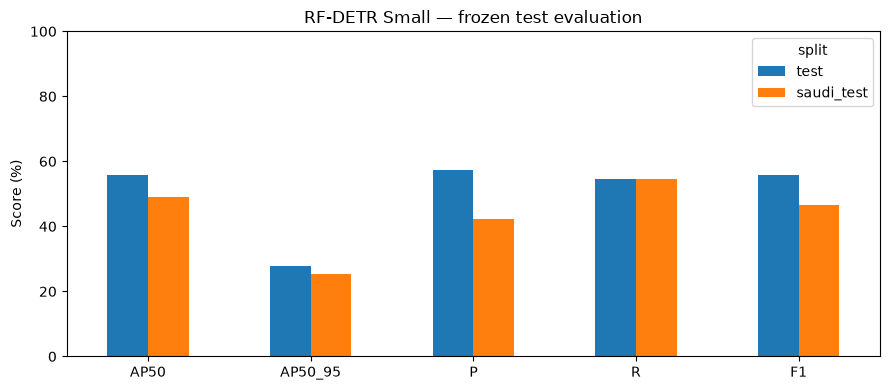

In [14]:
if RUN_DETECTION_EVALUATION:
    TEST_RECORDS={}; rows=[]; error_rows=[]
    thresholds=np.asarray(FROZEN['thresholds'])
    for split in ['test','saudi_test']:
        records=collect(PATHS[split],split); TEST_RECORDS[split]=records
        ap=ap_scores(records);point=operating(records,thresholds);exact=[]
        for rec in records:
            pred=rec['pred'];keep=pred[:,4]>=thresholds[pred[:,5].astype(int)]
            exact.append(set(rec['truth'][:,0].astype(int))==set(pred[keep,5].astype(int)))
            tp=int(match(rec['truth'],pred)[keep,0].sum())
            error_rows.append(dict(split=split,image=rec['image'],TP=tp,FP=int(keep.sum())-tp,FN=len(rec['truth'])-tp))
        for c in range(NC):
            rows.append(dict(split=split,method='rf',code=CODES[c],AP50=float(ap[c,0]),AP50_95=float(ap[c].mean()),
                **{k:float(point[k][c]) for k in ['P','R','F1','TP','FP','FN']}))
        rows.append(dict(split=split,method='rf',code='MACRO',AP50=float(ap[:,0].mean()),AP50_95=float(ap.mean()),
            P=float(point['P'].mean()),R=float(point['R'].mean()),F1=float(point['F1'].mean()),
            TP=int(point['TP'].sum()),FP=int(point['FP'].sum()),FN=int(point['FN'].sum()),
            image_exact_match=float(np.mean(exact)),images=len(records)))
    results=pd.DataFrame(rows);results.to_csv(OUTPUT/'final_metrics.csv',index=False)
    errors=pd.DataFrame(error_rows);errors.to_csv(OUTPUT/'image_errors.csv',index=False)
    summary=results[results.code=='MACRO'];display(summary.round(4))
    fig,ax=plt.subplots(figsize=(9,4))
    (summary.set_index('split')[['AP50','AP50_95','P','R','F1']].T*100).plot.bar(ax=ax,rot=0)
    ax.set(ylabel='Score (%)',ylim=(0,100),title='RF-DETR Small — frozen test evaluation')
    fig.tight_layout();fig.savefig(OUTPUT/'test_metrics.png',dpi=160);plt.show();plt.close(fig)

## 6. Optional visual detector inspection

Green: ground-truth boxes. Cyan: predictions at the frozen validation thresholds.
These examples are qualitative inspection, not a duplicate-evaluation dataset.

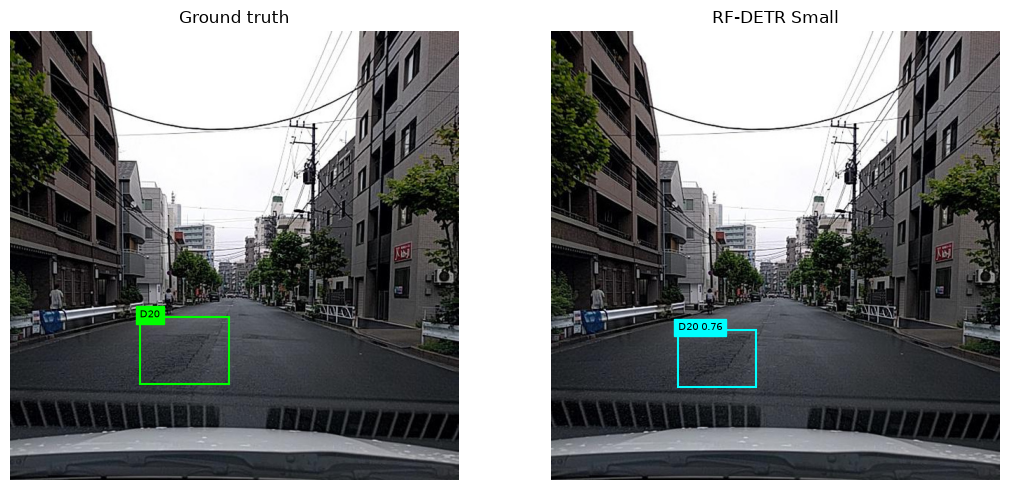

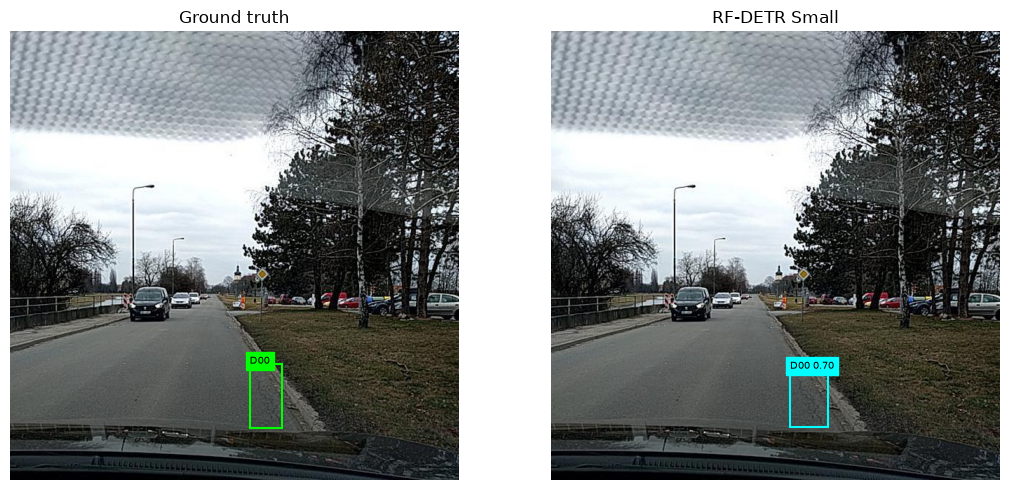

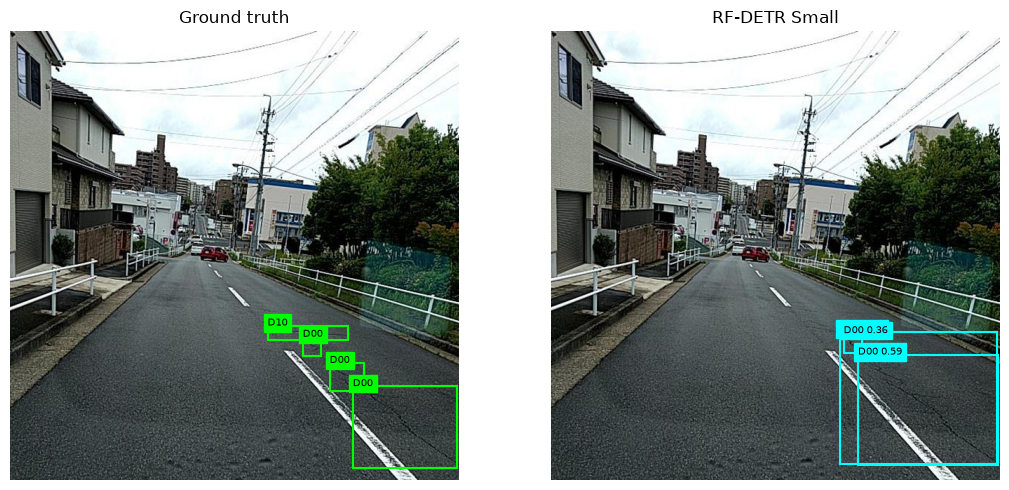

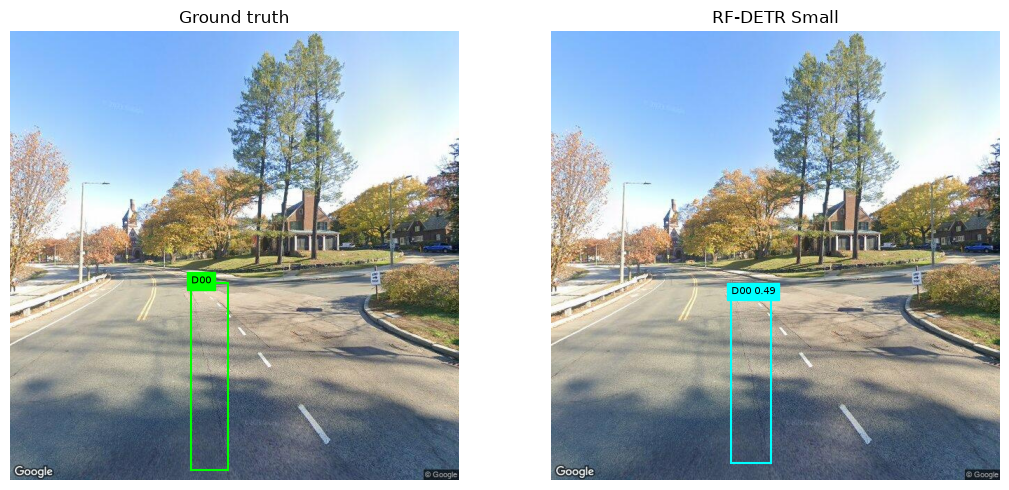

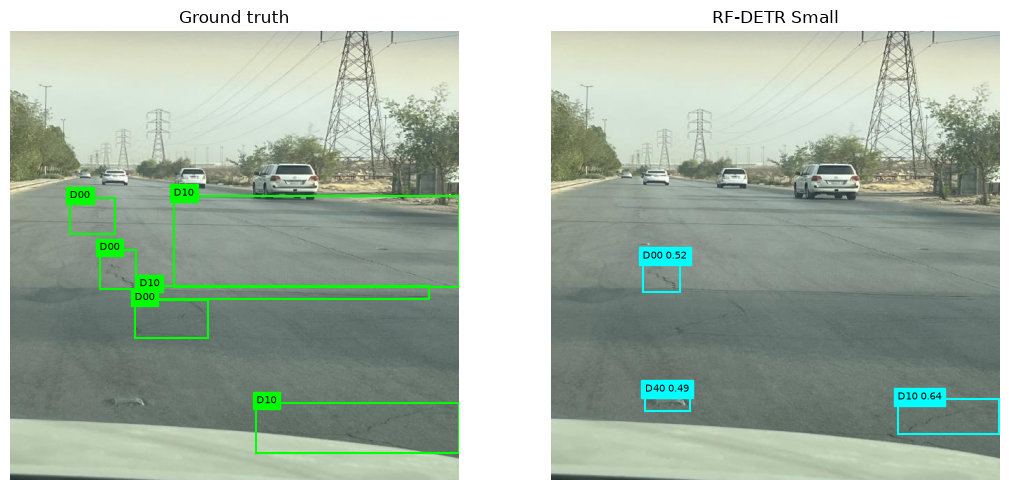

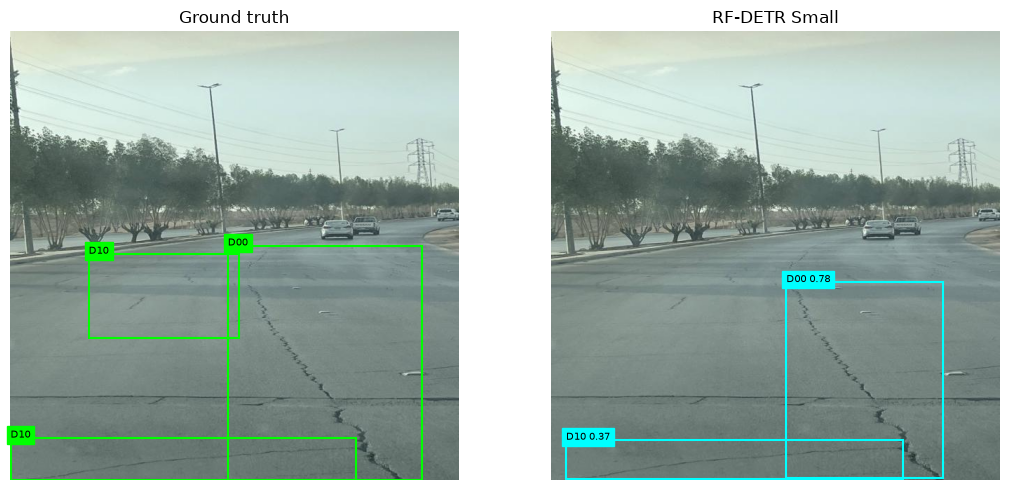

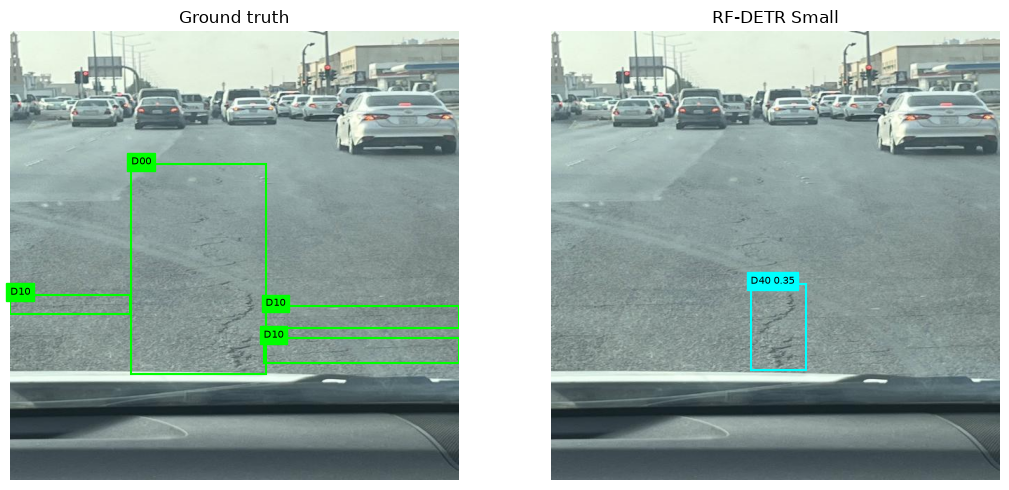

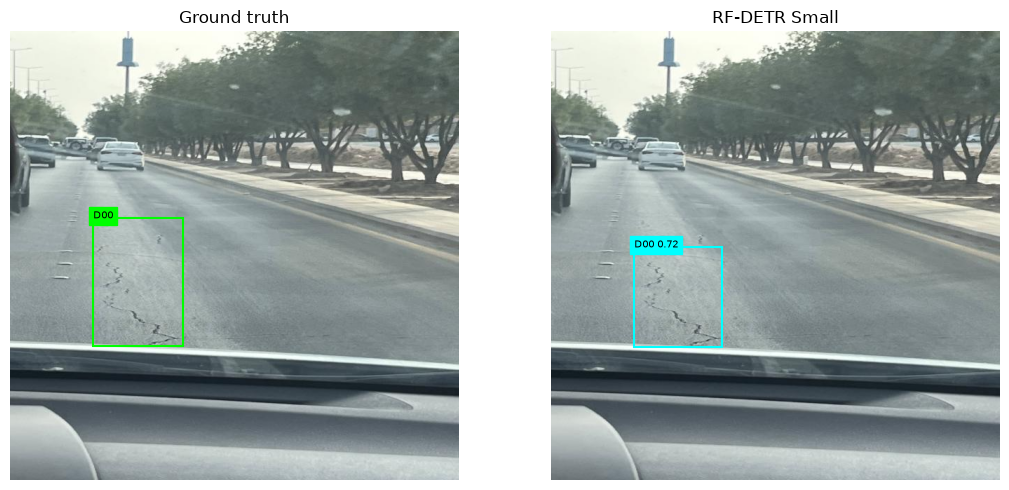

In [15]:
if RUN_DETECTION_EVALUATION:
    def draw(ax,boxes,predicted=False):
        for box in boxes:
            if predicted: x1,y1,x2,y2,conf,c=box
            else: c,x1,y1,x2,y2=box
            color='cyan' if predicted else 'lime'
            ax.add_patch(plt.Rectangle((x1,y1),x2-x1,y2-y1,fill=False,color=color,lw=1.5))
            text=CODES[int(c)]+(f' {conf:.2f}' if predicted else '')
            ax.text(x1,y1,text,color='black',backgroundcolor=color,fontsize=7)


    visual=OUTPUT/'visual_review';visual.mkdir(exist_ok=True)
    for split in ['test','saudi_test']:
        records=TEST_RECORDS[split]
        indices=random.Random(SEED).sample(range(len(records)),min(4,len(records)))
        for index in indices:
            rec=records[index]
            with Image.open(rec['image']) as im: image=np.asarray(im.convert('RGB'))
            pred=rec['pred'];keep=pred[:,4]>=thresholds[pred[:,5].astype(int)]
            fig,axes=plt.subplots(1,2,figsize=(11,5))
            for ax in axes:ax.imshow(image);ax.axis('off')
            draw(axes[0],rec['truth']);axes[0].set_title('Ground truth')
            draw(axes[1],pred[keep],True);axes[1].set_title('RF-DETR Small')
            fig.tight_layout();fig.savefig(visual/f'{split}_{index:04d}.png',dpi=130)
            plt.show();plt.close(fig)

## 7. Priority policy (experimental rules, not a learned maintenance standard)

Within each detected damage: severity = 0.40 * type value + 0.60 * normalized box size.
Type values: D00=.40, D10=.50, D20=.80, D40=1.00.
Normalized size = min(1, sqrt(box area / image area / per-class reference area)).
Reference areas: .05, .05, .25, .03. Type and size always belong to the same damage.
Image score = 100 * (.80 * maximum damage severity + .20 * log-scaled count), capped at 100.
Five or more detections saturate the count component.

Confidence has weight zero and is displayed separately. Low mean confidence OR low confidence
in a worst-severity detection triggers review, including tied worst detections.
Bands: Low <25, Medium <50, High <75, Critical >=75. Empty predictions: score 0, band None.
An empty detection result does not establish that the road is undamaged.

Maximum scores at full size and count: D00=80.8, D10=84, D20=93.6, D40=100.
All values and bands are experimental assumptions requiring maintenance-expert review.
Box area is a camera-dependent proxy, not physical damage area or depth.

In [16]:
PRIORITY_SOURCE=(ROOT/'src/roadscan/priority.py').read_text(encoding='utf-8')
exec(PRIORITY_SOURCE)
assert abs(sum(PRIORITY_CONFIG['weights'].values())-1)<1e-9
save_json(OUTPUT/'priority_config.json',PRIORITY_CONFIG)
print(json.dumps(PRIORITY_CONFIG,indent=1))
## NEW: validate the added within-damage weights.
assert all(v >= 0 for v in PRIORITY_CONFIG['severity_weights'].values())
assert abs(sum(PRIORITY_CONFIG['severity_weights'].values())-1) < 1e-9

{
 "type_weight": {
  "0": 0.4,
  "1": 0.5,
  "2": 0.8,
  "3": 1.0
 },
 "size_ref_area": {
  "0": 0.05,
  "1": 0.05,
  "2": 0.25,
  "3": 0.03
 },
 "severity_weights": {
  "type": 0.4,
  "size": 0.6
 },
 "weights": {
  "severity": 0.8,
  "count": 0.2,
  "confidence": 0.0
 },
 "count_ref": 5,
 "review_conf": 0.5,
 "bands": [
  [
   25,
   "Low"
  ],
  [
   50,
   "Medium"
  ],
  [
   75,
   "High"
  ],
  [
   101,
   "Critical"
  ]
 ]
}


,split,images,mean_priority,mean_truth_priority,MAE_vs_truth,spearman_vs_truth,band_agreement,needs_review_images
0,saudi_test,100,70.567,75.976,8.623,0.652,0.720,43
1,test,799,61.770,64.108,9.038,0.786,0.713,288


band,Critical,High,Medium,None
split,,,,
saudi_test,47,43,6,4
test,234,389,126,50


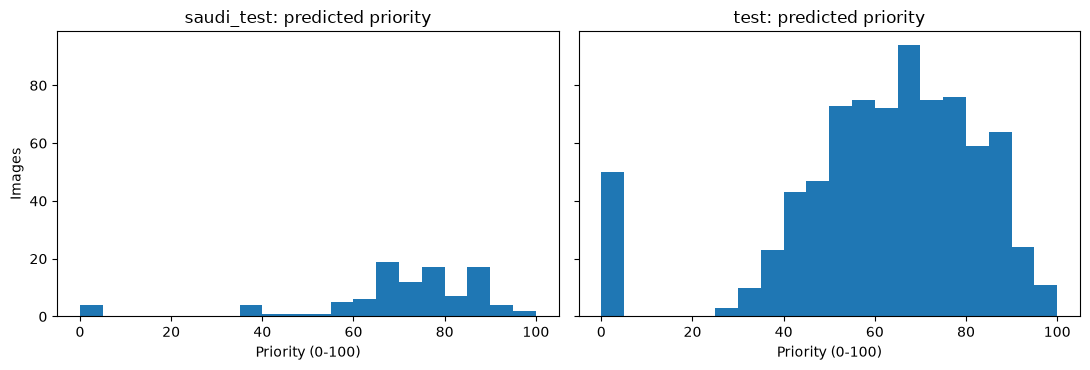

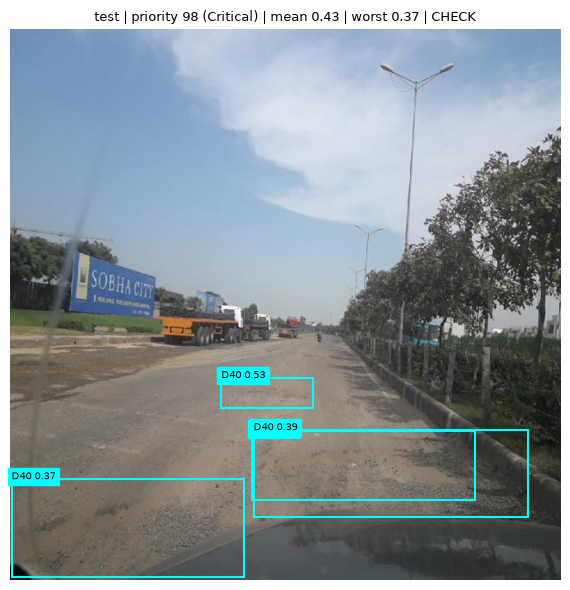

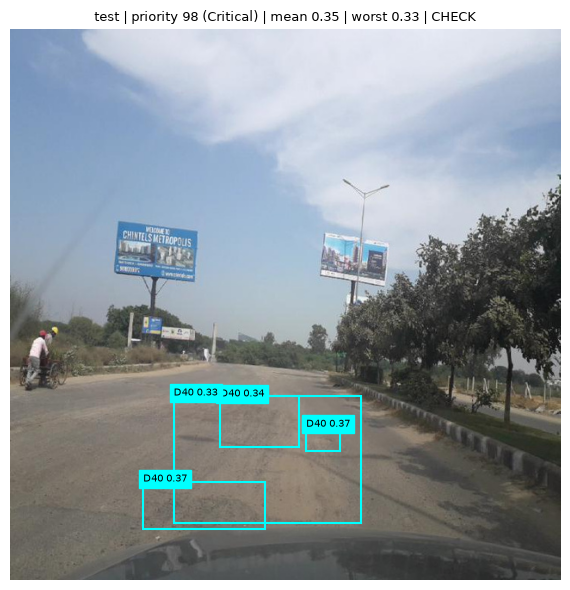

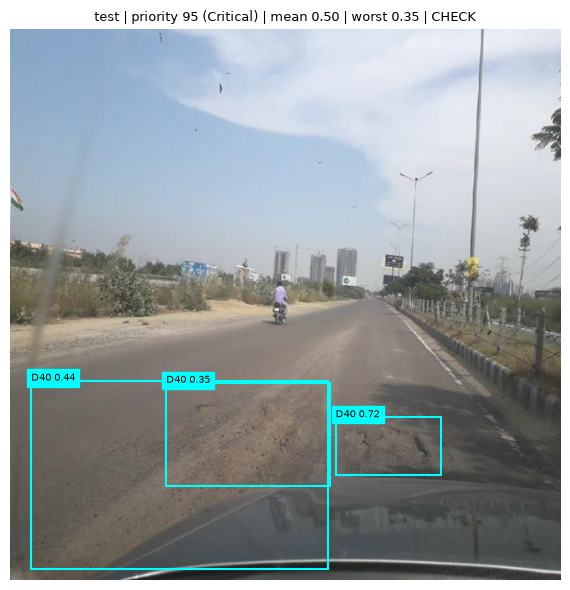

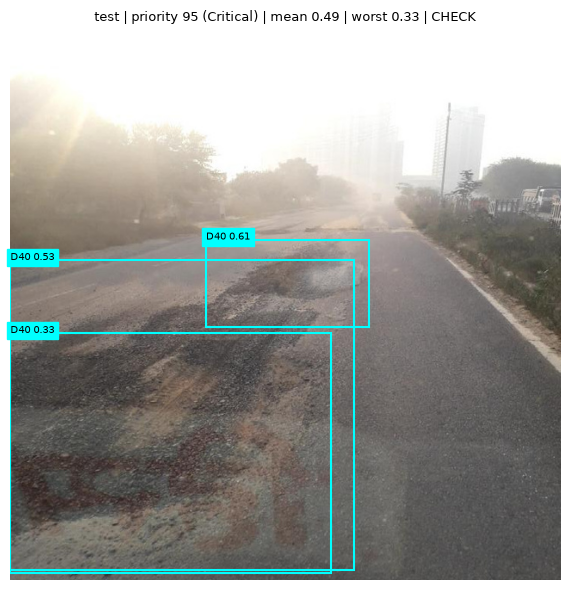

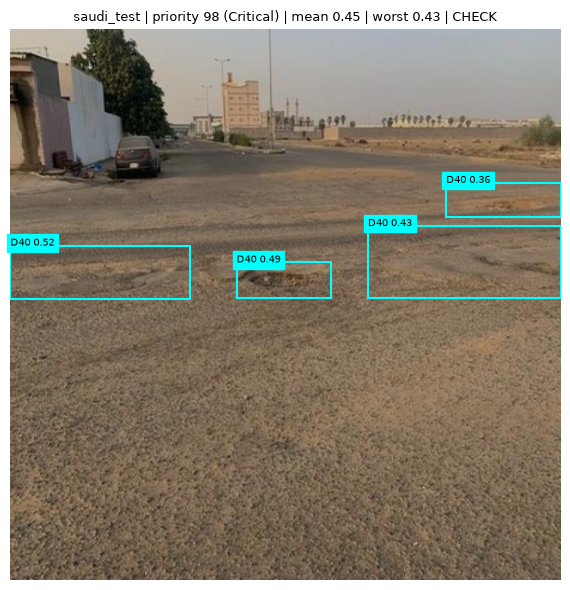

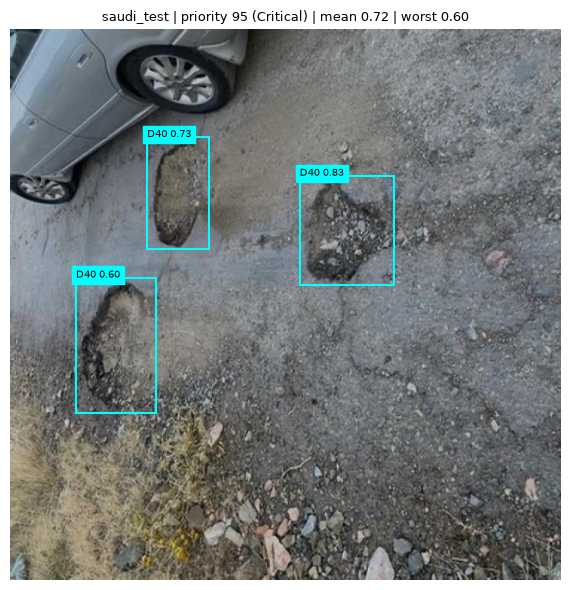

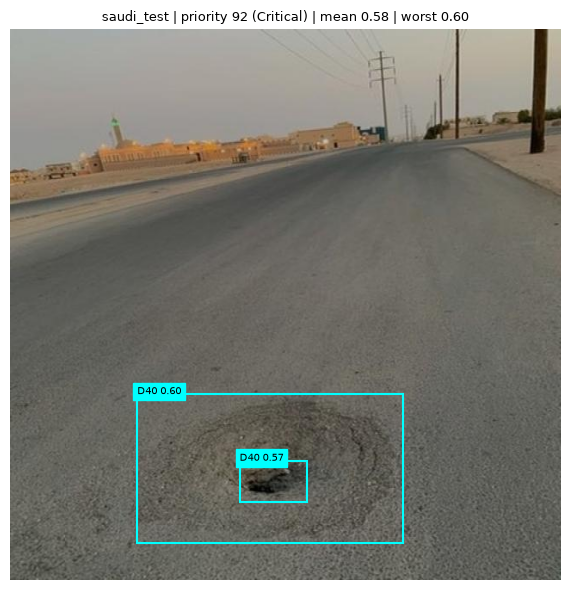

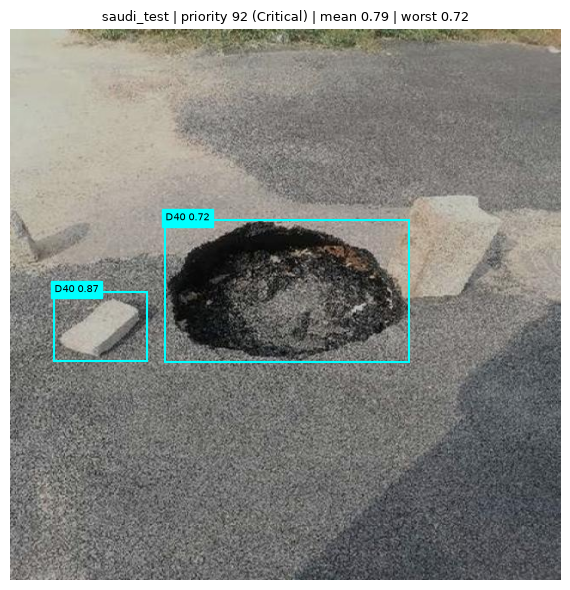

In [17]:
if RUN_DETECTION_EVALUATION:
    items=[]; rows=[]; det_rows=[]
    for split in ['test','saudi_test']:
        for rec in TEST_RECORDS[split]:
            pred=rec['pred']; keep=pred[:,4]>=thresholds[pred[:,5].astype(int)]
            kept=pred[keep]; name=Path(rec['image']).name
            p=priority_score(kept,rec['width'],rec['height'],PRIORITY_CONFIG)
            t=rec['truth']   # same score from ground-truth boxes (confidence = 1) as a reference
            g=priority_score(np.column_stack([t[:,1:5],np.ones(len(t)),t[:,0]]) if len(t) else np.empty((0,6)),
                             rec['width'],rec['height'],PRIORITY_CONFIG)
            items.append((split,kept,rec['width'],rec['height']))
            rows.append(dict(split=split,image=name,priority=p['score'],band=p['band'],detections=p['n'],
                worst_class=CODES[p['worst_class']] if p['worst_class']>=0 else '',worst_size=p['worst_size'],
                severity=p['severity'],count_score=p['count'],mean_conf=p['mean_conf'],needs_review=p['needs_review'],
                worst_conf=p['worst_conf'],review_reason=p['review_reason'],  ## NEW
                truth_priority=g['score'],truth_band=g['band']))
            sev,size=detection_severity(kept,rec['width'],rec['height'],PRIORITY_CONFIG)
            for d,(row,s,z) in enumerate(zip(kept,sev,size)):
                det_rows.append(dict(split=split,image=name,det=d,code=CODES[int(row[5])],confidence=row[4],
                    rel_size=z,severity=s))
    priority=pd.DataFrame(rows); priority.to_csv(OUTPUT/'priority_scores.csv',index=False)
    pd.DataFrame(det_rows).to_csv(OUTPUT/'priority_detections.csv',index=False)

    def spearman(a,b):
        ra,rb=pd.Series(a).rank().to_numpy(),pd.Series(b).rank().to_numpy()
        return float(np.corrcoef(ra,rb)[0,1]) if ra.std()>0 and rb.std()>0 else float('nan')

    summary_rows=[]
    for split,g in priority.groupby('split'):
        summary_rows.append(dict(split=split,images=len(g),mean_priority=g.priority.mean(),
            mean_truth_priority=g.truth_priority.mean(),MAE_vs_truth=float((g.priority-g.truth_priority).abs().mean()),
            spearman_vs_truth=spearman(g.priority,g.truth_priority),band_agreement=float((g.band==g.truth_band).mean()),
            needs_review_images=int(g.needs_review.sum())))
    priority_summary=pd.DataFrame(summary_rows); priority_summary.to_csv(OUTPUT/'priority_summary.csv',index=False)
    display(priority_summary.round(3))
    display(priority.groupby(['split','band']).size().unstack(fill_value=0))

    fig,axes=plt.subplots(1,2,figsize=(11,3.8),sharey=True)
    for ax,(split,g) in zip(axes,priority.groupby('split')):
        ax.hist(g.priority,bins=20,range=(0,100)); ax.set(title=f'{split}: predicted priority',xlabel='Priority (0-100)')
    axes[0].set_ylabel('Images'); fig.tight_layout(); fig.savefig(OUTPUT/'priority_hist.png',dpi=150); plt.show(); plt.close(fig)

    # Top-priority images per split; the score, band and mean confidence are printed on the picture.
    for split in ['test','saudi_test']:
        top=priority[priority.split==split].nlargest(4,'priority')
        for _,row in top.iterrows():
            rec=next(r for r in TEST_RECORDS[split] if Path(r['image']).name==row.image)
            with Image.open(rec['image']) as im: image=np.asarray(im.convert('RGB'))
            pred=rec['pred']; keep=pred[:,4]>=thresholds[pred[:,5].astype(int)]
            fig,ax=plt.subplots(figsize=(6,6)); ax.imshow(image); ax.axis('off'); draw(ax,pred[keep],True)
            flag=' | CHECK' if row.needs_review else ''
            ## NEW: expose confidence of the damage responsible for priority.
            wc = f'{row.worst_conf:.2f}' if pd.notna(row.worst_conf) else 'N/A'
            ax.set_title(f'{split} | priority {row.priority:.0f} ({row.band}) | mean {row.mean_conf:.2f} | worst {wc}{flag}',fontsize=9)
            fig.tight_layout(); fig.savefig(visual/f'priority_{split}_{Path(row.image).stem}.png',dpi=130); plt.show(); plt.close(fig)

In [18]:
if RUN_DETECTION_EVALUATION:
    ## NEW: this sensitivity experiment varies type values and image weights only.
    # Size references, within-damage weights and band boundaries remain fixed; this is not full policy validation.
    # Sensitivity: randomly change type weights and score weights by +-25% and see how much the ranking moves.
    rng=np.random.default_rng(SEED); records=[]
    base=priority.priority.to_numpy(); split_col=priority.split.to_numpy()
    for _ in range(200):
        cfg=json.loads(json.dumps(PRIORITY_CONFIG))
        for k in cfg['type_weight']: cfg['type_weight'][k]=float(np.clip(cfg['type_weight'][k]*rng.uniform(.75,1.25),0.05,1.0))
        a,b=cfg['weights']['severity']*rng.uniform(.75,1.25),cfg['weights']['count']*rng.uniform(.75,1.25)
        total=a+b+cfg['weights']['confidence']; cfg['weights']['severity'],cfg['weights']['count']=a/total,b/total
        cfg['weights']['confidence']/=total
        scores=np.array([priority_score(k,w,h,cfg)['score'] for _,k,w,h in items])
        bands=np.array([priority_score(k,w,h,cfg)['band'] for _,k,w,h in items])
        for split in ['test','saudi_test']:
            m=split_col==split
            records.append(dict(split=split,spearman=spearman(base[m],scores[m]),
                                band_same=float((bands[m]==priority.band.to_numpy()[m]).mean())))
    sensitivity=pd.DataFrame(records).groupby('split').agg(spearman_mean=('spearman','mean'),spearman_min=('spearman','min'),
        band_same_mean=('band_same','mean'),band_same_min=('band_same','min'))
    sensitivity.to_csv(OUTPUT/'priority_sensitivity.csv'); display(sensitivity.round(3))
    print('High Spearman = the image ranking is stable when weights change; lower band_same = band cut-offs are sensitive.')

,spearman_mean,spearman_min,band_same_mean,band_same_min
split,,,,
saudi_test,0.981,0.907,0.921,0.810
test,0.990,0.965,0.918,0.807


High Spearman = the image ranking is stable when weights change; lower band_same = band cut-offs are sensitive.


## 8. Materialize reusable application modules

## NEW: one implementation for both replay and the app
The following sources are embedded in this notebook. They provide persistent reports, open/closed
status, a query-before-insert transaction, missing-GPS handling, retained no-detection reports,
manual duplicate confirmation, and a reusable image-to-decision API.

These steps are skipped unless RUN_APP_EXPORT=True. Detection metrics and frozen thresholds do not depend on DINOv2 downloads.

In [19]:
# Optional application export; skipped in the default detection-only workflow.
if RUN_APP_EXPORT:
    # Package the same reusable modules used by the project notebooks.
    import uuid
    BUILD_ID=uuid.uuid4().hex[:12]
    PACKAGE=OUTPUT/'deployment_builds'/BUILD_ID/'deployment_package'
    PACKAGE.mkdir(parents=True,exist_ok=True)
    sources=ROOT/'src/roadscan'
    portable_service=(sources/'service.py').read_text(encoding='utf-8').replace(
        'from .predict import load_deployment, priority_score',
        'from predict import load_deployment, priority_score')
    portable_api=(sources/'api.py').read_text(encoding='utf-8').replace(
        'from .service import RoadScanService', 'from roadscan_app import RoadScanService')
    files={'roadscan_app.py':portable_service, 'app_example.py':portable_api,
           'predict.py':(sources/'predict.py').read_text(encoding='utf-8').replace('from .priority import', 'from priority import'),
           'priority.py':(sources/'priority.py').read_text(encoding='utf-8'),
           'duplicate_evaluation.py':(sources/'duplicate_evaluation.py').read_text(encoding='utf-8').replace('from .service import normalize_vectors', 'from roadscan_app import normalize_vectors'),
           'README.md':(ROOT/'docs/deployment.md').read_text(encoding='utf-8')}
    for name in ['requirements.txt','requirements-app.txt','requirements-evaluation.txt']:
        files[name]=(ROOT/name).read_text(encoding='utf-8')
    files['duplicate_pairs_template.csv']=(ROOT/'configs/duplicate_pairs_template.csv').read_text(encoding='utf-8')
    for name,content in files.items():
        (PACKAGE/name).write_text(content,encoding='utf-8')
    if str(PACKAGE) not in sys.path: sys.path.insert(0,str(PACKAGE))
    print('Deployment build:',PACKAGE)

else:
    print("Application export step skipped (RUN_APP_EXPORT=False).")


Application export step skipped (RUN_APP_EXPORT=False).


## 9. Frozen retrieval encoder

## NEW: save both the DINOv2 model and its exact image processor
This is a separate frozen DINOv2 Small encoder used for damage-crop retrieval, not an RF-DETR decoder.
It runs in evaluation/inference mode with gradients disabled. Embeddings are 384-dimensional,
L2-normalized CLS vectors. Loading the exported service uses only the saved encoder files.

In [20]:
# Optional application export; skipped in the default detection-only workflow.
if RUN_APP_EXPORT:
    from transformers import AutoImageProcessor, AutoModel
    from roadscan_app import DINOEncoder

    DINO_MODEL='facebook/dinov2-small'
    DINO_ENCODER_DIR=PACKAGE/'dinov2_encoder'
    processor=AutoImageProcessor.from_pretrained(DINO_MODEL,use_fast=False)
    dino=AutoModel.from_pretrained(DINO_MODEL)
    dino.eval().requires_grad_(False)
    DINO_ENCODER_DIR.mkdir(exist_ok=True)
    processor.save_pretrained(DINO_ENCODER_DIR)
    dino.save_pretrained(DINO_ENCODER_DIR,safe_serialization=True)
    del dino,processor
    gc.collect()
    DINO_FINGERPRINT=directory_hash(DINO_ENCODER_DIR)
    CROP_POLICY='exif_transpose_rgb_floor_ceil_box_no_padding_v1'
    encoder=DINOEncoder(DINO_ENCODER_DIR,device=INFERENCE_DEVICE,local_files_only=True)
    print('Frozen encoder dimension:',encoder.dimension)
    print('Encoder/processor fingerprint:',DINO_FINGERPRINT)
else:
    print("Application export step skipped (RUN_APP_EXPORT=False).")


Application export step skipped (RUN_APP_EXPORT=False).


## 10. Optional E5: calibrate and evaluate duplicate retrieval

## NEW: genuine labels are required; no synthetic accuracy is generated
Copy the header-only `duplicate_pairs_template.csv` and add real damage-crop pairs.
Columns: image_a, image_b, label, split, group_a, group_b.
Labels: 1=same physical defect, 0=different. Splits: validation/test. Groups identify physical defects,
not D00/D10/D20/D40. Groups cannot overlap between validation and test. Use different photos for positives.

The code compares pHash, ImageNet ResNet-18, and frozen DINOv2. It selects thresholds on validation
only and reports test precision, recall, F1, ROC AUC, Recall@1 and Recall@5. Retrieval gallery and
query counts are recorded. This tests visual retrieval, not real GPS accuracy.
When disabled or labels are absent, the threshold remains explicitly provisional at 0.80.

In [21]:
# Optional application export; skipped in the default detection-only workflow.
if RUN_APP_EXPORT:
    from duplicate_evaluation import evaluate_pairs

    DUP_EVALUATION=OUTPUT/'duplicate_evaluation'/BUILD_ID
    DUP_EVALUATION.mkdir(parents=True,exist_ok=True)
    if RUN_DUPLICATE_EVALUATION:
        if not Path(DUPLICATE_PAIRS_CSV).is_file():
            raise FileNotFoundError('Supply real labelled pairs before enabling RUN_DUPLICATE_EVALUATION.')
        evaluation_metrics,calibration=evaluate_pairs(DUPLICATE_PAIRS_CSV,DUP_EVALUATION,encoder,INFERENCE_DEVICE)
        calibration.update(embedding_fingerprint=DINO_FINGERPRINT,crop_policy=CROP_POLICY)
        save_json(DUP_EVALUATION/'calibration.json',calibration)
        display(evaluation_metrics.round(4))
    else:
        calibration=None
        save_json(DUP_EVALUATION/'evaluation_status.json',dict(status='not_run',reason='No confirmed duplicate-pair evaluation requested; no duplicate accuracy is claimed.'))
        print('E5 not run. Duplicate threshold remains provisional.')
else:
    print("Application export step skipped (RUN_APP_EXPORT=False).")


Application export step skipped (RUN_APP_EXPORT=False).


## 11. Export the application contract

## NEW: portable runtime artifacts and provenance
Only a freshly completed matching calibration can change the provisional threshold in this run.
The package keeps the detection configuration, priority rules, crop policy, saved encoder,
RF checkpoint hash and library versions together. Runtime state is separate and starts empty.

In [22]:
# Optional application export; skipped in the default detection-only workflow.
if RUN_APP_EXPORT:
    if calibration is not None:
        if calibration['embedding_fingerprint'] != DINO_FINGERPRINT or calibration['crop_policy'] != CROP_POLICY:
            raise ValueError('Calibration and deployment embedding/crop settings differ.')
        duplicate_threshold=float(calibration['methods']['dinov2']['threshold'])
        threshold_status='validation_calibrated'
    else:
        duplicate_threshold=0.80
        threshold_status='provisional'

    shutil.copy2(RF_BEST,PACKAGE/'rf_small.pth')
    APP_CONFIG={**FROZEN,'app_schema_version':1,'priority':PRIORITY_CONFIG,
        'duplicate_detection':dict(embedding_model=DINO_MODEL,embedding_dimension=384,
            embedding_fingerprint=DINO_FINGERPRINT,crop_policy=CROP_POLICY,
            similarity_metric='cosine',similarity_threshold=duplicate_threshold,
            threshold_status=threshold_status,gps_radius_m=100.0,
            gps_source='request_coordinates_only',search_policy='previous_open_original_reports_only',
            merge_policy='human_confirmation_required',
            calibration_manifest_sha256=calibration['manifest_sha256'] if calibration else None),
        'runtime_versions':dict(rfdetr=version('rfdetr'),transformers=version('transformers'),torch=str(torch.__version__))}
    save_json(PACKAGE/'deployment_config.json',APP_CONFIG)
    evidence_names=['frozen_selection.json','priority_config.json']
    if RUN_DETECTION_EVALUATION:
        evidence_names += ['priority_scores.csv','priority_summary.csv','priority_detections.csv',
                          'priority_sensitivity.csv','final_metrics.csv','image_errors.csv','protocol.json','dataset_identity.json']
    for name in evidence_names:
        if (OUTPUT/name).is_file(): shutil.copy2(OUTPUT/name,PACKAGE/name)
    shutil.copytree(DUP_EVALUATION,PACKAGE/'duplicate_evaluation',dirs_exist_ok=True)
    # Never include real user photos or a simulated test database in the portable model package.
    save_json(PACKAGE/'build_info.json',dict(build_id=BUILD_ID,rf_checkpoint_sha256=file_hash(PACKAGE/'rf_small.pth'),
        encoder_fingerprint=DINO_FINGERPRINT,duplicate_threshold_status=threshold_status,
        included_state='none',training_executed=MODE!='load',requested_total_epochs=RF_EPOCHS))
    print('App package ready:',PACKAGE)
    print('Duplicate threshold status:',threshold_status)
else:
    print("Application export step skipped (RUN_APP_EXPORT=False).")


Application export step skipped (RUN_APP_EXPORT=False).


## 12. Application calls and optional single-image smoke example

## NEW: load once and reuse; no dataset or retraining is needed by the app
Use `RoadScanService(package, persistent_state_dir)` in Streamlit, FastAPI or another UI.
The optional API adapter is included as `app_example.py`; its dependencies are separate.
For a new image pass real latitude/longitude, or pass neither and show the returned location-review flag.

```python
from roadscan_app import RoadScanService
service = RoadScanService("/path/to/deployment_package", "/persistent/app_state", device="cpu")
result = service.submit_report("photo.jpg", latitude=24.70, longitude=46.67)
queue = service.list_reports()
# Inspect first; never auto-confirm suggestions:
# service.review_duplicate(result["report_id"], confirm=True)
# service.resolve_report(original_report_id)
```

`open` and `pending_duplicate` remain visible in the priority queue. Only manually confirmed
duplicates and resolved originals leave that queue. Pending suggestions are not indexed as originals.
Submission uncertainty flags remain in the audit record after manual lifecycle changes.

In [23]:
if RUN_APP_SMOKE_EXAMPLE:
    from roadscan_app import RoadScanService
    if not APP_EXAMPLE_IMAGE: raise ValueError('Set APP_EXAMPLE_IMAGE before running the smoke example.')
    app_service=RoadScanService(PACKAGE,APP_STATE,device=INFERENCE_DEVICE,encoder=encoder)
    result=app_service.submit_report(APP_EXAMPLE_IMAGE,APP_EXAMPLE_LATITUDE,APP_EXAMPLE_LONGITUDE)
    print(json.dumps(result,indent=2,allow_nan=False))
else:
    print('App smoke example disabled; no live reports created.')

App smoke example disabled; no live reports created.


## 13. Optional simulated replay (workflow test only)

## NEW: process reports sequentially using the exact app service
Requires detector evaluation records. Every image, including no-detection reports, is retained.
GPS and arrival order are simulated and explicitly labelled. A fresh, separate database is used
on each replay. Replay counts are not duplicate precision/recall and do not tune the threshold.
No test vectors or simulated coordinates initialize the live application database.

In [24]:
if RUN_SIMULATED_REPLAY:
    if not RUN_DETECTION_EVALUATION: raise ValueError('Enable detector evaluation to create TEST_RECORDS for replay.')
    from roadscan_app import RoadScanService
    import tempfile
    replay_rng=np.random.default_rng(SEED)
    with tempfile.TemporaryDirectory(prefix='simulated_replay_',dir=OUTPUT) as replay_dir:
        replay=RoadScanService(PACKAGE,replay_dir,device=INFERENCE_DEVICE,detector=engine,encoder=encoder)
        replay_rows=[]
        for split in ['test','saudi_test']:
            for index,rec in enumerate(tqdm(TEST_RECORDS[split],desc=f'{split}: simulated replay')):
                lat,lon=24.0+replay_rng.normal(0,.002),39.0+replay_rng.normal(0,.002)
                report=replay.submit_report(rec['image'],lat,lon,report_id=f'{split}_{index:06d}')
                replay_rows.append(dict(report_id=report['report_id'],split=split,image=rec['image'],
                    decision=report['decision'],status=report['status'],gps_source='simulated',
                    priority=report['priority']['score'],threshold_status=report['threshold_status'],
                    match_report_id=report['match']['report_id'] if report['match'] else None))
        replay_table=pd.DataFrame(replay_rows)
        assert len(replay_table)==sum(len(TEST_RECORDS[s]) for s in ['test','saudi_test'])
        replay_table.to_csv(OUTPUT/'simulated_replay_results.csv',index=False)
        display(replay_table.groupby(['split','decision']).size().unstack(fill_value=0))
    print('Replay state removed. Live app state was not used. No duplicate-accuracy claim is made.')

## 14. Portable deployment and optional full training backup

The deployment ZIP includes all runtime sources, weights and the saved retrieval encoder.
Application reports are excluded. The training backup remains separate; inference weights do not
replace optimizer/scheduler state. Load-only exports do not claim to have run additional epochs.

In [25]:
# Optional application export; skipped in the default detection-only workflow.
if RUN_APP_EXPORT:
    # Static syntax check before creating the portable deployment archive.
    for path in PACKAGE.glob('*.py'): compile(path.read_text(encoding='utf-8'),str(path),'exec')
    archive=shutil.make_archive(str(OUTPUT/'RoadScan_RFDETRSmall_AppReady_Deployment'),'zip',root_dir=PACKAGE)
    print('Deployment ZIP:',archive)
else:
    print("Application export step skipped (RUN_APP_EXPORT=False).")


Application export step skipped (RUN_APP_EXPORT=False).


In [26]:
CREATE_TRAINING_BACKUP=(MODE != "load")
DOWNLOAD_DEPLOYMENT=False
if CREATE_TRAINING_BACKUP and full_checkpoint(RF_RUN) is not None:
    checkpoint=full_checkpoint(RF_RUN)
    backup=OUTPUT/'RoadScan_RFDETRSmall_Training_Backup.zip';temp=backup.with_suffix('.zip.tmp')
    with zipfile.ZipFile(temp,'w',compression=zipfile.ZIP_STORED) as z:
        for path in sorted(RF_RUN.rglob('*')):
            if path.is_file() and (path==checkpoint or path.name.startswith('checkpoint_best_')
                                  or path.suffix in {'.json','.csv','.yaml'}):
                z.write(path,Path('rf_small_training')/path.relative_to(RF_RUN))
    temp.replace(backup);print('Portable training backup:',backup)
if DOWNLOAD_DEPLOYMENT and not RUN_APP_EXPORT:
    raise ValueError("Enable RUN_APP_EXPORT before downloading a deployment package.")
if DOWNLOAD_DEPLOYMENT:
    from google.colab import files
    files.download(archive)
print('All results:',OUTPUT)

All results: C:\Users\ameer\Downloads\RoadScan_Detection_GitHub\RoadScan_Detection_GitHub\RoadScan_GitHub\reports\rf_appready


## 15. Acceptance and reporting checklist

- Default `MODE="load"` does not train; detector validation/evaluation is enabled and app export is disabled. Exact resume uses the actual checkpoint epoch and a total of 20.
- Keep AP50, AP50-95, F1, class-presence exact match, priority agreement and duplicate metrics distinct.
- The trained detector artifact and its validation thresholds must match by SHA-256.
- The app accepts new images without loading test datasets, normalizes EXIF orientation, and persists reports.
- Missing GPS and no-detection reports stay visible for review. No fake GPS is generated in production calls.
- Only earlier open originals are searched. Suggestions require a human confirmation; no circular merging.
- The default duplicate threshold is provisional. Supply disjoint labelled validation/test groups for E5.
- pHash/ResNet/DINO comparisons and ROC/Recall@K are available, but no scores exist until real pairs are supplied.
- Real local field validation, civil-engineering priority calibration, CPU latency measurement and UI integration
  remain deployment acceptance tasks. A downloadable notebook alone is not proof of operational accuracy.

References: [RF-DETR](https://rfdetr.roboflow.com/),
[DINOv2](https://github.com/facebookresearch/dinov2), [FAISS](https://github.com/facebookresearch/faiss).